# Sudan electricity forecasting: data recovery and reproducible checks
**Lahmeyer International / Ministry of Water Resources and Electricity · report 260690 · 18 October 2012**  
Prepared for the PyPSA-Sudan research project · analysis date 26 September 2026

This notebook recovers the report's numerical annexes, redraws its demand and adequacy results, and independently checks the arithmetic that is visible in the PDF. It provides useful historical inputs for a post-war least-cost electrification study.

**What this is:** a partial replication of a 2012 demand forecast and supply-adequacy assessment.  
**What is still unavailable:** the original forecasting workbook and complete underlying utility time series. Replotting published outputs is labelled separately from recalculating them. This is not a new least-cost optimization or an observed 2022 system reconstruction.

The report combines **2006–2011 electricity observations, 2008 census inputs, 2012 asset assessments and 2012–2031 projections**. Its 15 states and 131 localities use historical boundaries. Every source page below means the physical PDF page, starting at 1, because printed page numbers restart.

Run all cells in order using the existing `pypsa` conda environment. The supplied CSVs make this notebook independent of the original PDF and of internet access. The extraction script can rebuild them when given the original file.

In [1]:
from pathlib import Path
import calendar, json, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data' / 'national_forecast.csv').exists():
    raise FileNotFoundError('Run this notebook from the Sudan_Forecasting_Replication directory.')
DATA, RESULTS, FIG = ROOT/'data', ROOT/'results', ROOT/'results'/'figures'
RESULTS.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
def read(name): return pd.read_csv(DATA / (name + '.csv'))
national, states, access = read('national_forecast'), read('state_forecast'), read('state_access_forecast')
history, plants, hydro = read('historical_consumption'), read('plant_characteristics'), read('hydro_monthly')
localities, annual, monthly = read('localities_2008_2012'), read('annual_supply_balance'), read('monthly_supply_balance')
colors = {'Moderate':'#16877d','Base':'#285aa0','High':'#d79524'}
sectors = ['domestic','industrial','commercial','agricultural','governmental']
sector_colors = ['#3679a8','#de9150','#64a18c','#bec269','#8772a6']
plt.rcParams.update({'figure.dpi':115,'axes.spines.top':False,'axes.spines.right':False,
                     'axes.grid':True,'grid.alpha':0.2,'axes.titleweight':'bold', 'font.size':10})
pd.set_option('display.max_columns',10)
pd.set_option('display.max_colwidth',None)
def finish(name):
    plt.savefig(FIG/(name+'.png'),dpi=180,bbox_inches='tight')
    plt.savefig(FIG/(name+'.svg'),bbox_inches='tight')
    plt.show()
checks=[]
def check(label, errors, tolerance, unit):
    a=pd.Series(np.asarray(errors).flatten()).dropna().abs()
    checks.append(dict(check=label, maximum_absolute_error=float(a.max()), tolerance=tolerance,
                       unit=unit, n_compared=len(a), passed=bool((a<=tolerance+1e-8).all())))
print(f'{len(plants)} plant/configuration records; {len(localities)} localities; '
      f'{len(national)} national scenario-years; {len(monthly)} monthly scenario records')
display(national.loc[national.year.isin([2022,2031]),
        ['scenario','year','billed_gwh','sent_out_gwh','peak_mw','grid_access_pct']].round(1))

19 plant/configuration records; 131 localities; 60 national scenario-years; 720 monthly scenario records


,scenario,year,billed_gwh,sent_out_gwh,peak_mw,grid_access_pct
10,Base,2022,23067.0,27592.0,5053.0,65.6
19,Base,2031,34268.0,40990.0,7427.0,71.2
30,High,2022,26182.0,31318.0,5735.0,76.5
39,High,2031,38574.0,46141.0,8361.0,80.1
50,Moderate,2022,20015.0,23942.0,4385.0,53.5
59,Moderate,2031,30036.0,35928.0,6510.0,61.6


## 1. What was extracted

| Dataset | Coverage | PDF pages | Interpretation |
|---|---|---|---|
| National forecasts | Three scenarios, 2012–2031; 59 metrics per scenario-year | 126, 128, 130 | Model outputs from 2012 |
| State demand and access | 15 states, national and western aggregates | 127, 129, 131 | Forecasts; exclude aggregate rows when summing states |
| Electricity consumption | 15 states × 5 sectors × 6 years, plus national totals | 119 | Historical utility consumption in GWh |
| Plant characteristics | 19 units/groups/configurations; costs, fuel, coordinates, efficiency | 120 | Existing and proposed assets; two replacement configurations |
| Plant generation | 2007–2011 gross and net rows | 120 | Missing cells retained; not all plants operated in all years |
| Hydro and heat rates | Eight hydro configurations × 12 months × four metrics; 11 thermal groups × nine load levels | 121 | Historical/planning performance, not 2022 inflows |
| Localities and demographics | 131 locality records; 2008 census and population projections | 114–115, 123–124 | Historical boundaries and assumptions |
| Supply balances | Three annual scenarios and 240 months per scenario | 132–133 | Published adequacy calculations, including planned plants |
| Transmission | Voltage/length summary; 37 planned routes | 56, 62 | Route information; not a complete line-rating dataset |
| GDP | Sector history and CBS/IMF growth comparison | 117 | Context; GDP was not the forecast driver |

The extraction identified **98 automatic table blocks**, including main-text tables and the original data-request checklist (p.112). Raw page exports are retained locally and are not included in this public repository. The normalized datasets above have explicit row mappings and numerical checks. Run `extract_data.py` with your own source PDF to regenerate the raw exports for checking.

In [2]:
inventory=[]
for f in sorted(DATA.glob('*.csv')):
    d=pd.read_csv(f)
    inventory.append({'file':f.name,'rows':len(d),'columns':len(d.columns)})
display(pd.DataFrame(inventory))

,file,rows,columns
0,annual_supply_balance.csv,60,12
1,historical_consumption.csv,480,7
2,historical_gdp.csv,132,8
3,hydro_monthly.csv,96,8
4,hydro_monthly_long.csv,384,6
5,implementation_crosscheck_2019.csv,6,6
6,localities_2008_2012.csv,131,19
7,monthly_supply_balance.csv,720,13
8,national_forecast.csv,60,63
9,national_forecast_long.csv,3540,10


## 2. Recreate the published demand scenarios

The study combined historical trends with bottom-up connections and grid extension, rather than estimating an econometric demand model. Planned-line construction rates were 100/150/200 km per year per project path for Moderate/Base/High; committed projects used twice those rates (pp.86–87). It assumed sufficient generation and transmission capacity when forecasting demand.

The following figures **replot recovered outputs**. They do not regenerate the unavailable connection workbook. A large industrial step in 2017 is linked to assumed connection of 150 MW of captive load in Port Sudan and 65 MW near Atbara (p.87 and demand discussion). At a 90% load factor, these loads correspond to about 1,695 GWh/year; the reported industrial jump can also include ordinary growth.

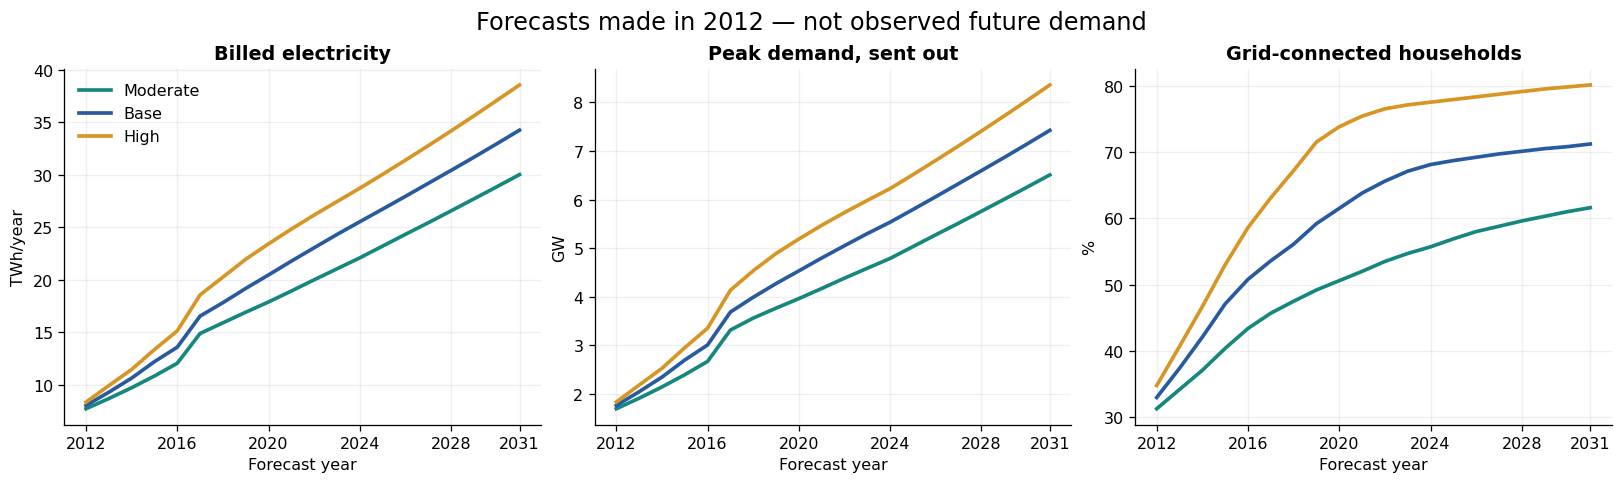

Captive-load assumption: 1695.06 GWh/year


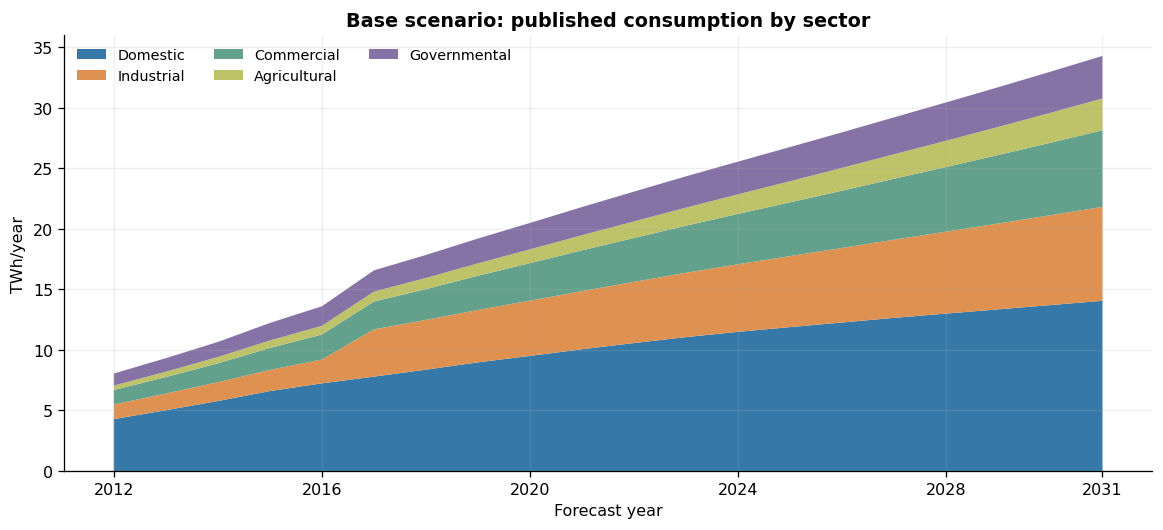

In [3]:
fig,ax=plt.subplots(1,3,figsize=(14,4.1),layout='constrained')
for scenario,c in colors.items():
    d=national[national.scenario==scenario].sort_values('year')
    for a,col,scale,title,unit in zip(ax,['billed_gwh','peak_mw','grid_access_pct'],[1000,1000,1],
                  ['Billed electricity','Peak demand, sent out','Grid-connected households'],['TWh/year','GW','%']):
        a.plot(d.year,d[col]/scale,label=scenario,color=c,lw=2.3)
        a.set(title=title,xlabel='Forecast year',ylabel=unit)
        a.set_xticks([2012,2016,2020,2024,2028,2031])
ax[0].legend(frameon=False)
fig.suptitle('Forecasts made in 2012 — not observed future demand',fontsize=15)
finish('01_national_forecast')
print('Captive-load assumption:', (150+65)*0.9*8760/1000, 'GWh/year')

base=national[national.scenario=='Base'].sort_values('year')
fig,ax=plt.subplots(figsize=(10,4.5),layout='constrained')
ax.stackplot(base.year,*[base[s+'_gwh']/1000 for s in sectors],labels=[s.title() for s in sectors],colors=sector_colors)
ax.set(title='Base scenario: published consumption by sector',xlabel='Forecast year',ylabel='TWh/year')
ax.set_xticks([2012,2016,2020,2024,2028,2031])
ax.legend(loc='upper left',frameon=False,ncol=3,fontsize=9)
finish('09_base_sector_forecast')

## 3. Independently reconstruct losses and load factor

Transmission loss is measured against sent-out generation, while distribution loss is measured after transmission. Consequently:

\[
G_y=\frac{C_y}{(1-t)(1-d_y)},\qquad
d_y=\max(0.12,\ 0.134-(y-2011)\,0.014/5).
\]

Here \(C_y\) is billed consumption, \(G_y\) is sent-out generation, and \(t=0.05\). This reconstructs the distribution-loss reduction from 13.4% in 2011 to 12% in 2016 (p.83). Adding 5% and 12% as an uplift to consumption would be incorrect. At the final rates, losses are **16.4% of sent-out energy** and generation must be **19.62% above billed consumption**.

Peak power is \(P_y=1000G_y/(8760 LF_y)\). The printed load factors are rounded to whole percentages, so they cannot recover each peak exactly. A fixed 8760-hour convention is used here to examine the report's annual calculation; this is not a calendar-resolved dispatch simulation.

In [4]:
recalc=national.copy()
recalc['distribution_rate_reconstructed']=np.maximum(.12,.134-(recalc.year-2011)*.014/5)
recalc['sent_out_recalculated_gwh']=recalc.billed_gwh/((1-.05)*(1-recalc.distribution_rate_reconstructed))
recalc['energy_error_gwh']=recalc.sent_out_recalculated_gwh-recalc.sent_out_gwh
recalc['peak_from_rounded_lf_mw']=recalc.sent_out_gwh*1000/(8760*recalc.load_factor_pct/100)
recalc['implied_load_factor_pct']=recalc.sent_out_gwh*1000/(8760*recalc.peak_mw)*100
check('Sequential loss reconstruction',recalc.energy_error_gwh,1,'GWh')
check('Printed energy accounting',national.sent_out_gwh-national.transmission_loss_gwh-national.distribution_loss_gwh-national.billed_gwh,1,'GWh')
check('Sector consumption adds to national',national[[s+'_gwh' for s in sectors]].sum(axis=1)-national.billed_gwh,3,'GWh')
check('Load factor agrees within printed precision',recalc.implied_load_factor_pct-recalc.load_factor_pct,.51,'percentage points')
recalc.to_csv(RESULTS/'demand_reconstruction.csv',index=False)
display(recalc.groupby('scenario').agg(max_energy_error_gwh=('energy_error_gwh',lambda s:s.abs().max()),
          implied_lf_min_pct=('implied_load_factor_pct','min'),implied_lf_max_pct=('implied_load_factor_pct','max')).round(4))

,max_energy_error_gwh,implied_lf_min_pct,implied_lf_max_pct
scenario,,,
Base,0.8182,61.0039,63.0085
High,0.8716,61.0027,63.0053
Moderate,0.8086,60.9960,63.0052


## 4. Historical demand by region and sector

These are **2011 observations**, not 2022 regional consumption. They offer evidence for regional demand allocation where more recent readings are unavailable. Modern boundary changes and post-war population displacement require separate treatment.

The 15 charts use equal-size pies to compare sector shares; the title of each chart gives its absolute annual consumption, so a small state is not mistaken for a large load centre. Annex 4, p.119.

Published national consumption: 6,690 GWh
Khartoum + Al Gezira share: 74.89%


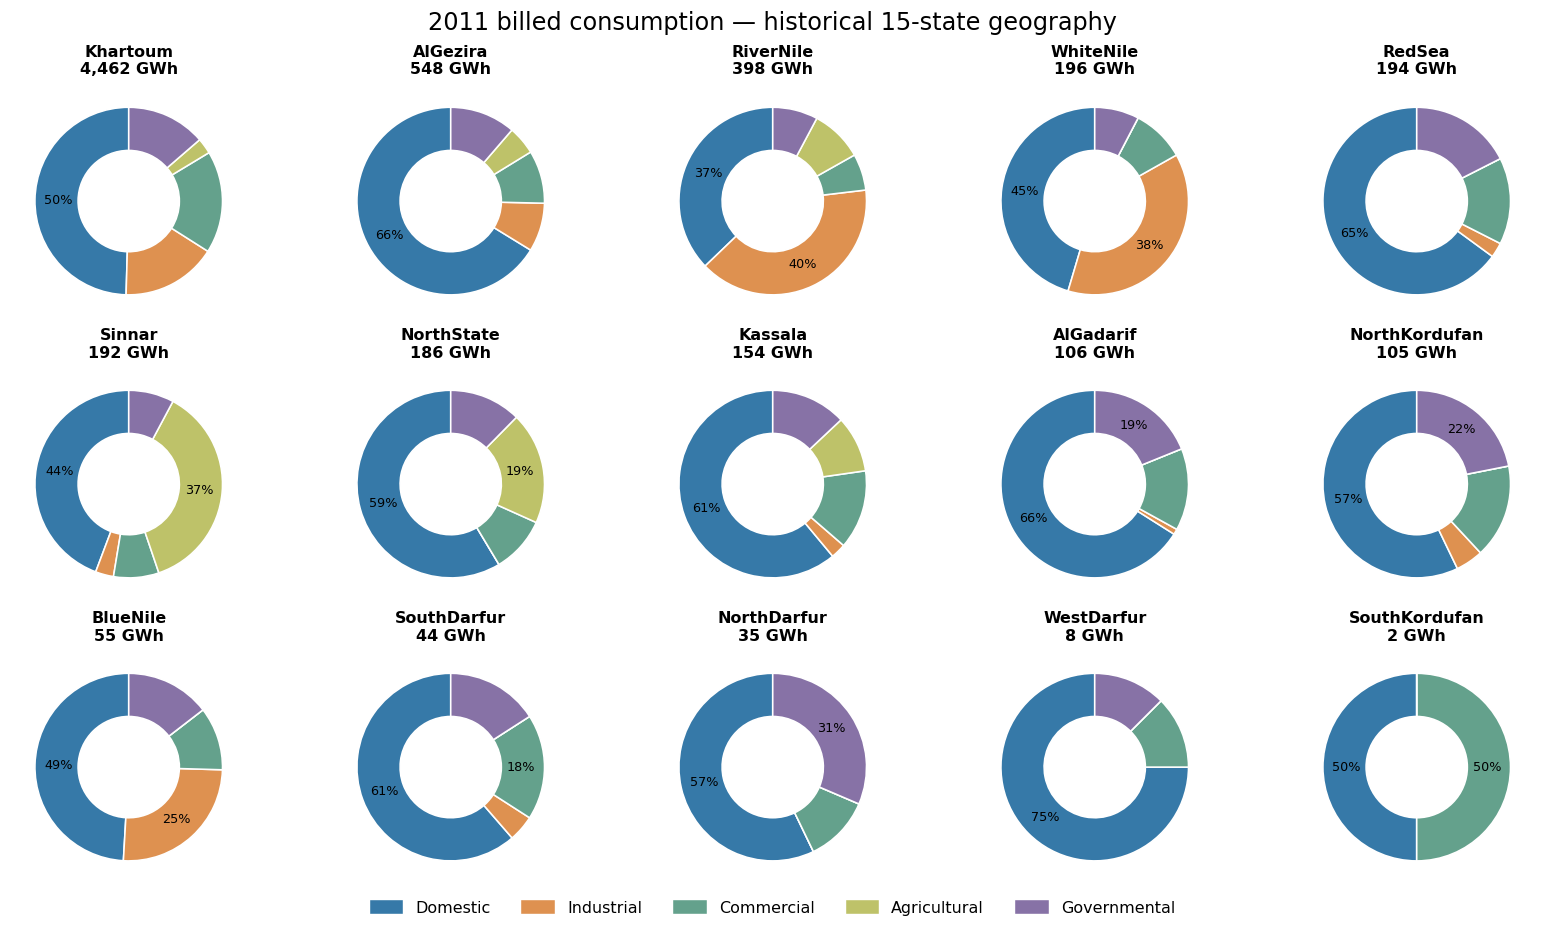

In [5]:
h11=history[(history.year==2011)&(~history['aggregate'])]
region=h11.pivot(index='state',columns='sector',values='consumption_gwh')[sectors]
nat11=history[(history.year==2011)&history['aggregate']].set_index('sector').consumption_gwh
regional_total=region.sum(axis=1).sort_values(ascending=False)
print(f'Published national consumption: {nat11.sum():,.0f} GWh')
print(f'Khartoum + Al Gezira share: {regional_total.loc[["Khartoum","AlGezira"]].sum()/nat11.sum()*100:.2f}%')
check('Historical state sums versus national by year/sector',
    history[~history['aggregate']].groupby(['year','sector']).consumption_gwh.sum()-
    history[history['aggregate']].set_index(['year','sector']).consumption_gwh,8,'GWh')
fig,axes=plt.subplots(3,5,figsize=(14,8),layout='constrained')
for ax,state in zip(axes.flat,regional_total.index):
    values=region.loc[state]
    ax.pie(values,colors=sector_colors,startangle=90,wedgeprops={'width':.46,'edgecolor':'white'},
           autopct=lambda p:f'{p:.0f}%' if p>=18 else '',pctdistance=.75,textprops={'fontsize':8})
    ax.set_title(f'{state}\n{values.sum():,.0f} GWh',fontsize=10)
fig.suptitle('2011 billed consumption — historical 15-state geography',fontsize=15)
fig.legend(handles=[Patch(color=c,label=s.title()) for s,c in zip(sectors,sector_colors)],
           loc='outside lower center',ncol=5,frameon=False)
finish('02_state_sector_pies_2011')
regional_total.rename('consumption_gwh').to_csv(RESULTS/'state_totals_2011.csv')

## 5. Plant locations and performance inputs

The table distinguishes gross nameplate capacity from net maximum capacity. The 19 entries are not 19 separate operating stations: some are unit groups at the same location, six are committed projects in the 2012 assessment, and Roseires dam heightening and Sennar upgrading are replacement configurations. **Never add the original and replacement capacity together.**

The plot below uses only records marked existing in 2012 and aggregates co-located units. Coordinates are rounded report coordinates, not surveyed locations. No transmission connections are inferred from this scatter plot.

The O&M costs are reported USD/kW/year and USD/MWh; they do not include fuel, investment or post-war repair costs. Their price basis needs verification before economic reuse. Annex 4, p.120.

,name,status_in_2012,gross_capacity_mw,net_max_capacity_mw,primary_fuel,fixed_om_usd_per_kw_year,variable_om_usd_per_mwh
0,Khartoum North 1,exists,30.0,27.7,HCGO,20.0,1.0
1,Khartoum North 2,exists,30.0,27.7,HCGO,20.0,1.0
2,Khartoum North 3+4,exists,120.0,110.0,HFO,20.0,1.0
3,Khartoum North 5+6,exists,200.0,190.0,HFO,12.0,4.3
4,Khartoum North GT,exists,50.0,33.6,Gasoil,20.0,12.0
5,Garri 1 blocks 1+2,exists,180.0,170.0,Gasoil,20.0,2.2
6,Garri 2 blocks 1+2,exists,180.0,170.0,Gasoil,20.0,2.2
7,Garri 4 units 1+2,exists,110.0,99.7,Sponge Coke,28.0,6.2
8,Red Sea,committed,600.0,534.0,Coal,60.0,1.0
9,Al Fula,committed,405.0,380.7,Gas Blend (Neem),20.0,1.0


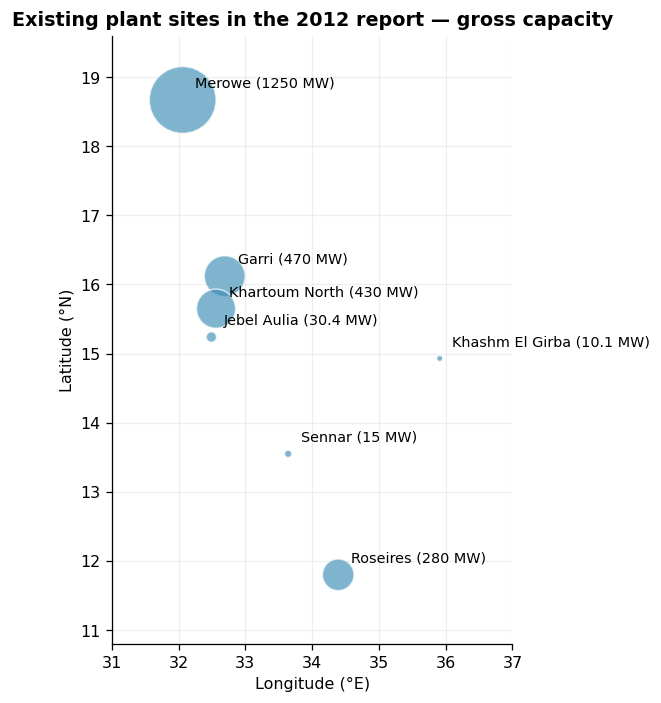

In [6]:
display(plants[['name','status_in_2012','gross_capacity_mw','net_max_capacity_mw','primary_fuel',
                'fixed_om_usd_per_kw_year','variable_om_usd_per_mwh']])
existing=plants[plants.status_in_2012=='exists'].copy()
existing['site']=existing.name.replace({name:'Khartoum North' for name in existing.name if name.startswith('Khartoum North')})
existing.loc[existing.name.str.startswith('Garri'),'site']='Garri'
sites=existing.groupby(['site','latitude','longitude'],as_index=False).agg(capacity=('gross_capacity_mw','sum'))
fig,ax=plt.subplots(figsize=(8,6),layout='constrained')
ax.scatter(sites.longitude,sites.latitude,s=sites.capacity*1.4,color='#398cb4',alpha=.65,edgecolor='white')
for r in sites.itertuples():
    ax.annotate(f'{r.site} ({r.capacity:g} MW)',(r.longitude,r.latitude),xytext=(8,8),textcoords='offset points',fontsize=9)
ax.set(xlabel='Longitude (°E)',ylabel='Latitude (°N)',title='Existing plant sites in the 2012 report — gross capacity')
ax.set_xlim(31,37);ax.set_ylim(10.8,19.6)
ax.set_aspect(1/np.cos(np.deg2rad(15)))
finish('03_existing_plant_locations')

## 6. Reconstruct hydro seasonality and thermal efficiency

The report separates minimum power, dependable maximum power, firm power and mean daily energy. These describe different planning quantities and must not be used interchangeably as PyPSA availability factors. In particular, a monthly mean energy budget is not a mandatory hourly generation profile or a reservoir inflow series.

The calculation below integrates mean daily energy using a 365-day reference year and compares it with the annual planned mean. Merowe and several other rows agree closely, but Roseires and Sennar do not reconcile. We preserve those discrepancies. The profiles predate later upstream developments and cannot establish post-war hydrology.

,name,mean_energy_gwh,generation_planned_average_gwh,difference_gwh
plant_id,,,,
Jeb-HP,Jebel Aulia,67.508,68.0,-0.492
KhE-HP,Khashm El Girba,68.590,69.0,-0.410
M-HP,Merowe,5865.008,5865.0,0.008
ResD-HP,Roseires dam heightening,1468.482,1468.0,0.482
Ros-HP,Roseires,1078.276,1141.0,-62.724
Sen-HP,Sennar,62.603,69.0,-6.397
SenU-HP,Sennar upgrading,105.063,105.0,0.063
UpA-HP,Upper Atbara,834.416,834.0,0.416


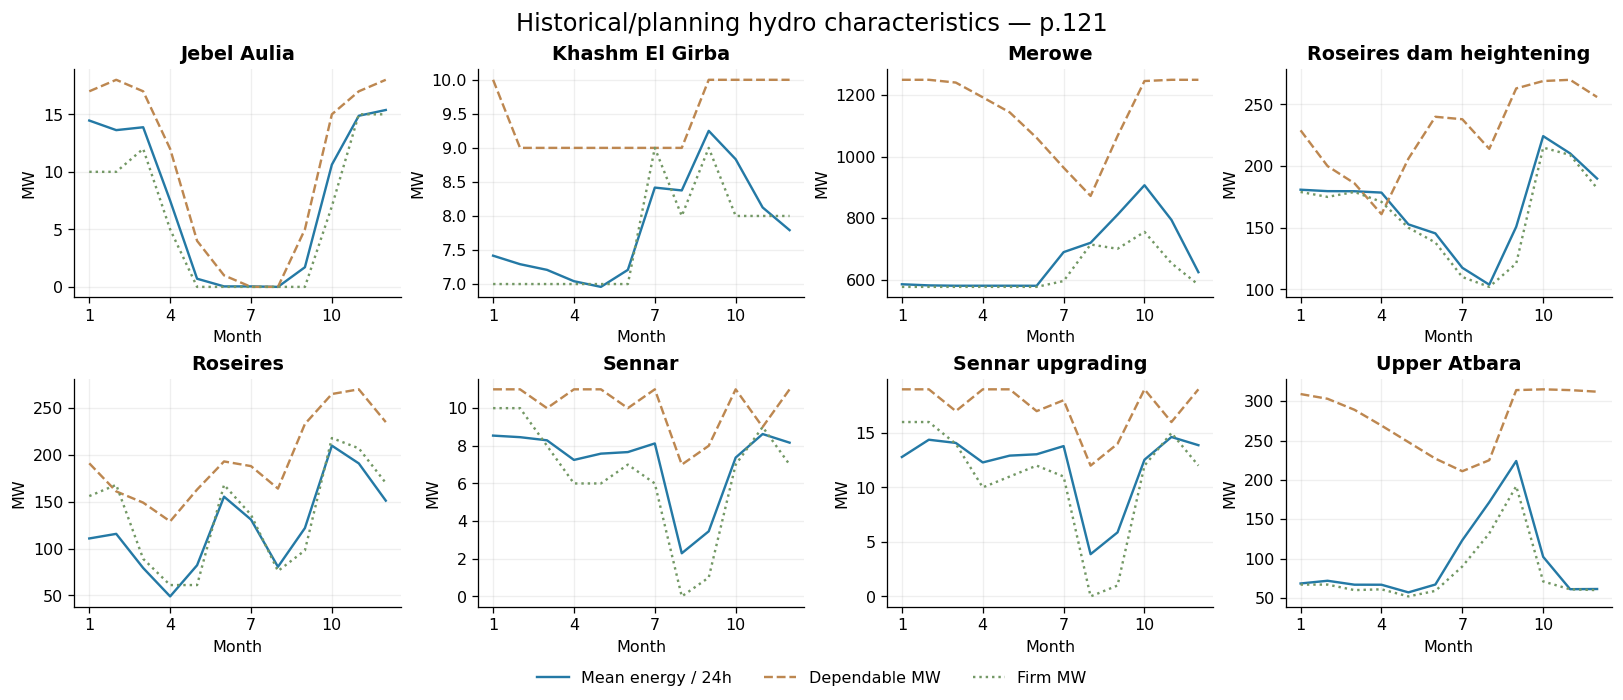

,name,efficiency_pct,efficiency_from_heat_rate_pct,difference_pp
0,Khartoum North 1,29.4,29.38,-0.02
1,Khartoum North 2,29.4,29.38,-0.02
2,Khartoum North 3+4,32.4,32.38,-0.02
3,Khartoum North 5+6,35.3,35.27,-0.03
4,Khartoum North GT,24.2,24.21,0.01
5,Garri 1 blocks 1+2,43.3,43.35,0.05
6,Garri 2 blocks 1+2,43.3,43.35,0.05
7,Garri 4 units 1+2,32.3,32.32,0.02
8,Red Sea,36.7,36.77,0.07
9,Al Fula,36.7,33.32,-3.38


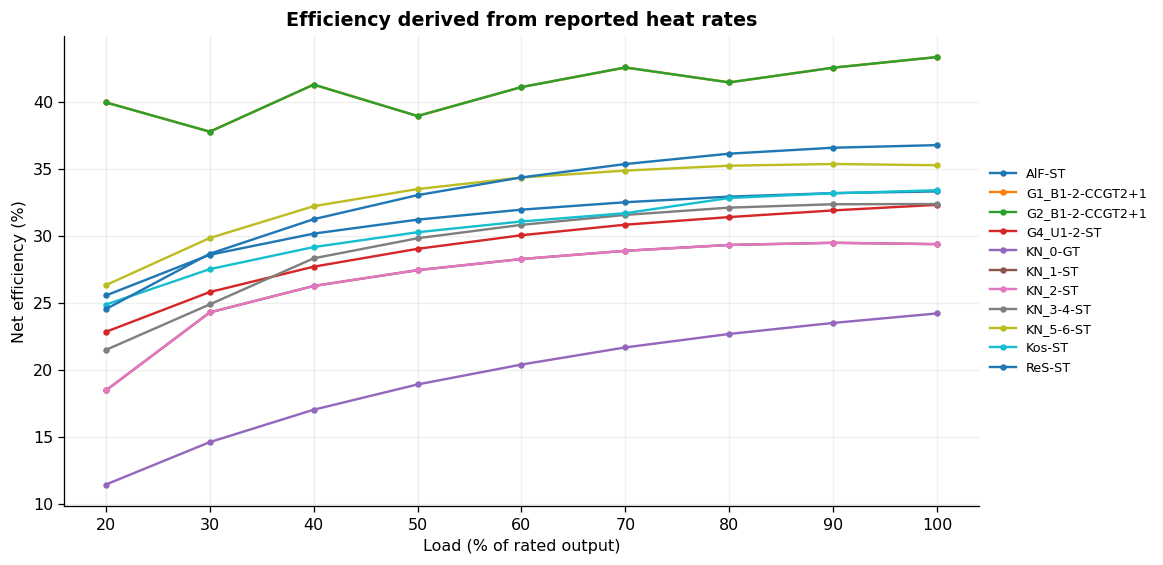

In [7]:
hydro['days_reference_year']=hydro.month.map(lambda m:calendar.monthrange(2011,int(m))[1])
hydro['mean_energy_gwh']=hydro.mean_generation_mwh_per_day*hydro.days_reference_year/1000
hydro_annual=hydro.groupby('plant_id').mean_energy_gwh.sum().to_frame().join(
    plants.set_index('plant_id')[['name','generation_planned_average_gwh','net_max_capacity_mw']])
hydro_annual['difference_gwh']=hydro_annual.mean_energy_gwh-hydro_annual.generation_planned_average_gwh
display(hydro_annual[['name','mean_energy_gwh','generation_planned_average_gwh','difference_gwh']].round(3))
hydro_annual.to_csv(RESULTS/'hydro_annual_reconciliation.csv')
fig,axes=plt.subplots(2,4,figsize=(14,6),layout='constrained')
for ax,(pid,g) in zip(axes.flat,hydro.groupby('plant_id')):
    ax.plot(g.month,g.mean_generation_mwh_per_day/24,label='Mean energy / 24h',color='#2479a5')
    ax.plot(g.month,g.dependable_mw,label='Dependable MW',color='#bd8750',ls='--')
    ax.plot(g.month,g.firm_mw,label='Firm MW',color='#739865',ls=':')
    ax.set(title=plants.set_index('plant_id').loc[pid,'name'],ylabel='MW',xticks=[1,4,7,10],xlabel='Month')
fig.legend(*axes.flat[0].get_legend_handles_labels(),loc='outside lower center',ncol=3,frameon=False)
fig.suptitle('Historical/planning hydro characteristics — p.121',fontsize=15)
finish('04_hydro_seasonality')

heat=read('thermal_heat_rates')
heat['efficiency_from_heat_rate_pct']=3600/heat.heat_rate_kj_per_kwh*100
comparison=heat[heat.load_pct==100].merge(plants[['plant_id','name','efficiency_pct']],on='plant_id')
comparison['difference_pp']=comparison.efficiency_from_heat_rate_pct-comparison.efficiency_pct
display(comparison[['name','efficiency_pct','efficiency_from_heat_rate_pct','difference_pp']].round(2))
comparison.to_csv(RESULTS/'thermal_efficiency_reconciliation.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4.8),layout='constrained')
for pid,g in heat.groupby('plant_id'):
    ax.plot(g.load_pct,g.efficiency_from_heat_rate_pct,marker='.',label=pid)
ax.set(xlabel='Load (% of rated output)',ylabel='Net efficiency (%)',title='Efficiency derived from reported heat rates')
ax.legend(loc='center left',bbox_to_anchor=(1,0.5),frameon=False,fontsize=8)
finish('05_thermal_efficiency')

## 7. Recalculate annual adequacy and reproduce the supply-gap charts

The annual annex uses a 15% peak reserve. For each scenario we independently calculate:

\[
R=0.15P,\quad P_{required}=1.15P,\quad
\Delta P=P_{available}-P_{required},\quad
\Delta E=E_{firm}-E_{demand}.
\]

Negative values are deficits. These are adequacy calculations against the report's **existing-plus-committed fleet**, not optimized capacity additions or simulated unserved energy. A reserve deficit does not itself equal consumer load shedding. Annex 6, p.132; assumptions and caveats p.103.

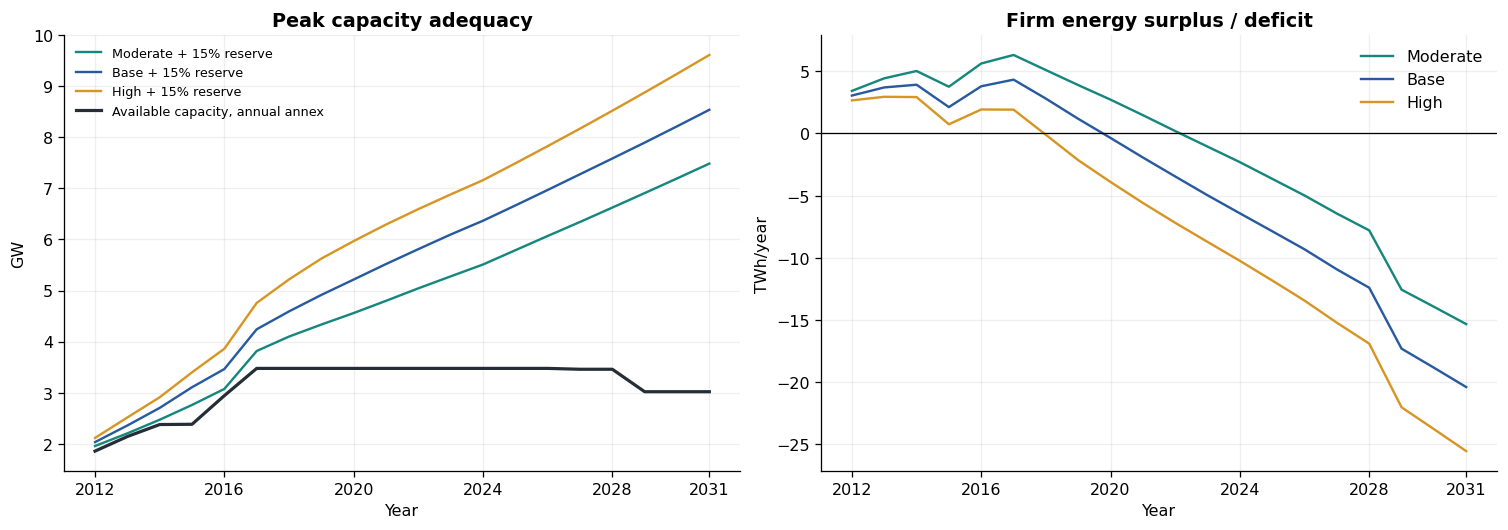

,year,capacity_mw,peak_mw,required_mw,power_gap_mw,firm_energy_gwh,energy_demand_gwh,energy_gap_gwh
39,2031,3017.0,7427.0,8541.0,-5524.0,20604.0,40990.0,-20386.0


In [8]:
annual['reserve_recalculated_mw']=annual.peak_mw*.15
annual['required_recalculated_mw']=annual.peak_mw*1.15
annual['power_gap_recalculated_mw']=annual.capacity_mw-annual.required_recalculated_mw
annual['energy_gap_recalculated_gwh']=annual.firm_energy_gwh-annual.energy_demand_gwh
check('Annual reserve = 15% peak',annual.reserve_mw-annual.reserve_recalculated_mw,.6,'MW')
check('Annual power gap arithmetic',annual.capacity_mw-annual.required_mw-annual.power_gap_mw,1,'MW')
check('Annual energy gap arithmetic',annual.energy_gap_recalculated_gwh-annual.energy_gap_gwh,1,'GWh')
annual.to_csv(RESULTS/'annual_balance_recalculated.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for scenario,c in colors.items():
    d=annual[annual.scenario==scenario]
    ax[0].plot(d.year,d.required_recalculated_mw/1000,color=c,label=scenario+' + 15% reserve')
    ax[1].plot(d.year,d.energy_gap_recalculated_gwh/1000,color=c,label=scenario)
one=annual[annual.scenario=='Base']
ax[0].plot(one.year,one.capacity_mw/1000,color='#252e37',lw=2,label='Available capacity, annual annex')
ax[0].set(title='Peak capacity adequacy',xlabel='Year',ylabel='GW');ax[0].legend(fontsize=8,frameon=False)
ax[1].axhline(0,color='black',lw=.8)
ax[1].set(title='Firm energy surplus / deficit',xlabel='Year',ylabel='TWh/year');ax[1].legend(frameon=False)
for a in ax: a.set_xticks([2012,2016,2020,2024,2028,2031])
finish('06_annual_supply_adequacy')
display(annual[(annual.year==2031)&(annual.scenario=='Base')][
    ['year','capacity_mw','peak_mw','required_mw','power_gap_mw','firm_energy_gwh','energy_demand_gwh','energy_gap_gwh']])

## 8. Monthly analysis and discrepancies in the source

The monthly annex is dated **16 August 2012**, while national forecast annexes are dated **18 October 2012**. This may explain some differences, but the exact workbook revision history is unavailable.

Monthly required capacity implies about 273–274 MW reserve in 2012–2015, 276–277 MW in 2016 and 534 MW from 2017. That resembles the contingency-based interpretation discussed in the prose and **differs from a consistent 15% margin**. We reproduce the printed arithmetic and separately calculate the 15% alternative; we do not silently overwrite the report.

Available monthly capacity is blank for February–December 2031 in the PDF. Those entries remain missing. The printed power-gap rows still exist; reverse-solving capacity from them would be a derived estimate, not an extracted observation.

,min,max
year,,
2012,273.0,274.0
2013,273.0,274.0
2014,273.0,274.0
2015,273.0,274.0
2016,276.0,277.0
2017,534.0,534.0
2018,534.0,534.0
2019,534.0,534.0
2020,534.0,534.0


,scenario,year,monthly_energy_sum_gwh,energy_demand_gwh,energy_difference_gwh
39,High,2031,45119.0,46141.0,-1022.0
38,High,2030,43389.0,44368.0,-979.0
37,High,2029,41678.0,42616.0,-938.0
36,High,2028,40002.0,40900.0,-898.0
35,High,2027,38360.0,39219.0,-859.0


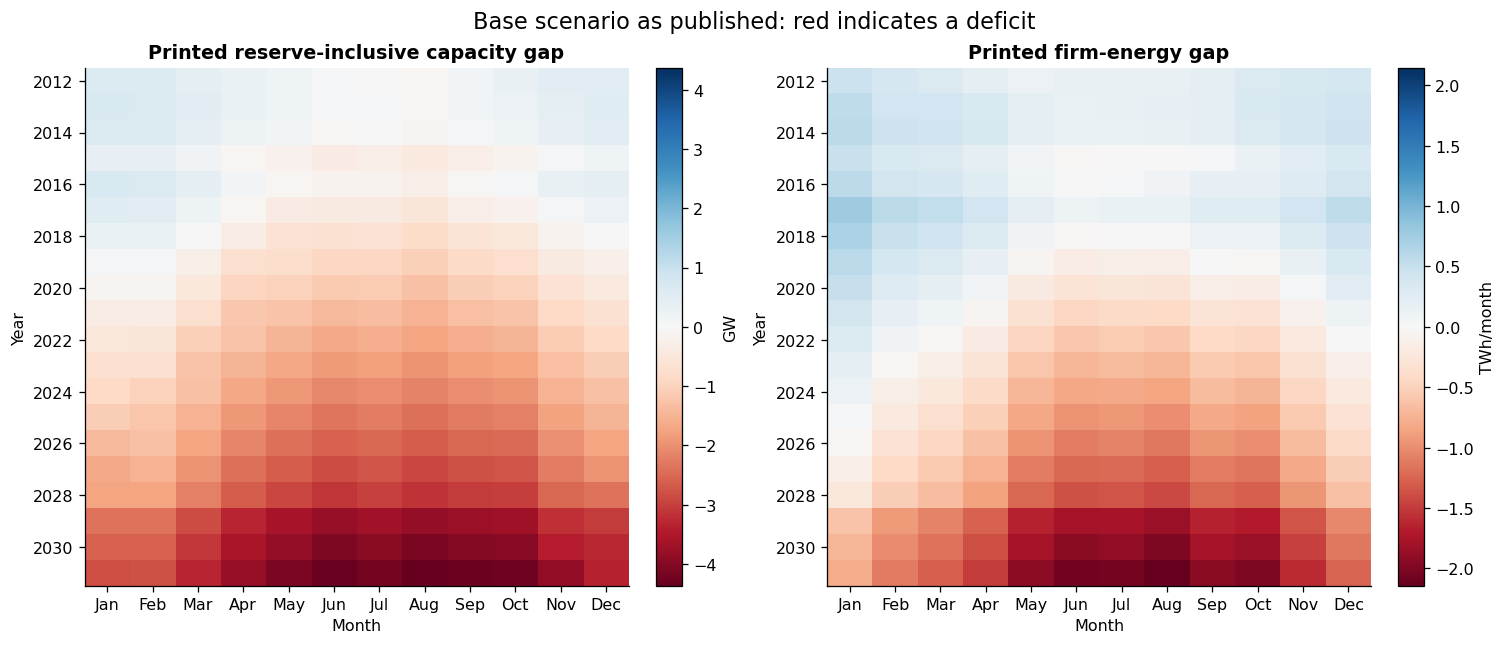

In [9]:
monthly['implied_reserve_mw']=monthly.required_mw-monthly.peak_mw
monthly['power_gap_consistent_15pct_mw']=monthly.capacity_mw-1.15*monthly.peak_mw
check('Monthly power gap arithmetic where capacity exists',monthly.capacity_mw-monthly.required_mw-monthly.power_gap_mw,1,'MW')
check('Monthly energy gap arithmetic',monthly.firm_energy_gwh-monthly.energy_demand_gwh-monthly.energy_gap_gwh,1,'GWh')
monthly.to_csv(RESULTS/'monthly_balance_recalculated.csv',index=False)
month_year=monthly.groupby(['scenario','year']).agg(monthly_energy_sum_gwh=('energy_demand_gwh','sum'),
             minimum_monthly_capacity_mw=('capacity_mw','min'),months_with_capacity=('capacity_mw','count')).reset_index()
month_year=month_year.merge(annual[['scenario','year','energy_demand_gwh','capacity_mw']],on=['scenario','year'])
month_year['energy_difference_gwh']=month_year.monthly_energy_sum_gwh-month_year.energy_demand_gwh
month_year.to_csv(RESULTS/'annual_monthly_comparison.csv',index=False)
display(monthly.groupby('year').implied_reserve_mw.agg(['min','max']))
display(month_year.loc[month_year.energy_difference_gwh.abs().nlargest(5).index,
                       ['scenario','year','monthly_energy_sum_gwh','energy_demand_gwh','energy_difference_gwh']])
fig,ax=plt.subplots(1,2,figsize=(13,5.5),layout='constrained')
base=monthly[monthly.scenario=='Base']
for a,col,title,scale in zip(ax,['power_gap_mw','energy_gap_gwh'],
                          ['Printed reserve-inclusive capacity gap','Printed firm-energy gap'],[1000,1000]):
    mat=base.pivot(index='year',columns='month',values=col)/scale
    im=a.imshow(mat,aspect='auto',cmap='RdBu',vmin=-abs(mat.to_numpy()).max(),vmax=abs(mat.to_numpy()).max())
    a.set(xticks=range(12),xticklabels=list(calendar.month_abbr)[1:],yticks=range(0,20,2),
          yticklabels=mat.index[::2],title=title,xlabel='Month',ylabel='Year')
    a.grid(False);fig.colorbar(im,ax=a,label='GW' if col=='power_gap_mw' else 'TWh/month')
fig.suptitle('Base scenario as published: red indicates a deficit',fontsize=14)
finish('07_monthly_adequacy')

## 9. Electrification and locality inputs

The source contains location-level population, household size, grid status, route distance and planned/committed labels. It does **not** provide locality coordinates or a cost-optimal choice between grid, mini-grid and standalone systems.

Zero route distance for an unconnected locality with no listed project must not be interpreted as free connection. Off-grid access in the forecast is a target-filling assumption, not a technology-selection result. The text states state-level minimum access of 50/60/70% for Moderate/Base/High (p.87), whereas the annex's lowest final values are checked below. “Grid-connected” in this report also includes large isolated grids (p.31), not only the interconnected national network.

,localities,population_2008,households_2008
state,,,
(AKlaGsasadba)rif,1,91875.0,17668.0
AlGadarif,9,1256503.0,222354.0
AlGezira,7,3575280.0,593045.0
BlueNile,6,832130.0,145998.0
Kassala,11,1789806.0,321935.0
Khartoum,7,5274321.0,870081.0
NorthDarfur,12,2113626.0,371362.0
NorthKordufan,9,2920992.0,544797.0
NorthState,7,699065.0,117890.0


Unconnected localities with zero listed distance: 3


,minimum_state_access_in_annex_pct
scenario,
Base,60.0
High,70.0
Moderate,60.0


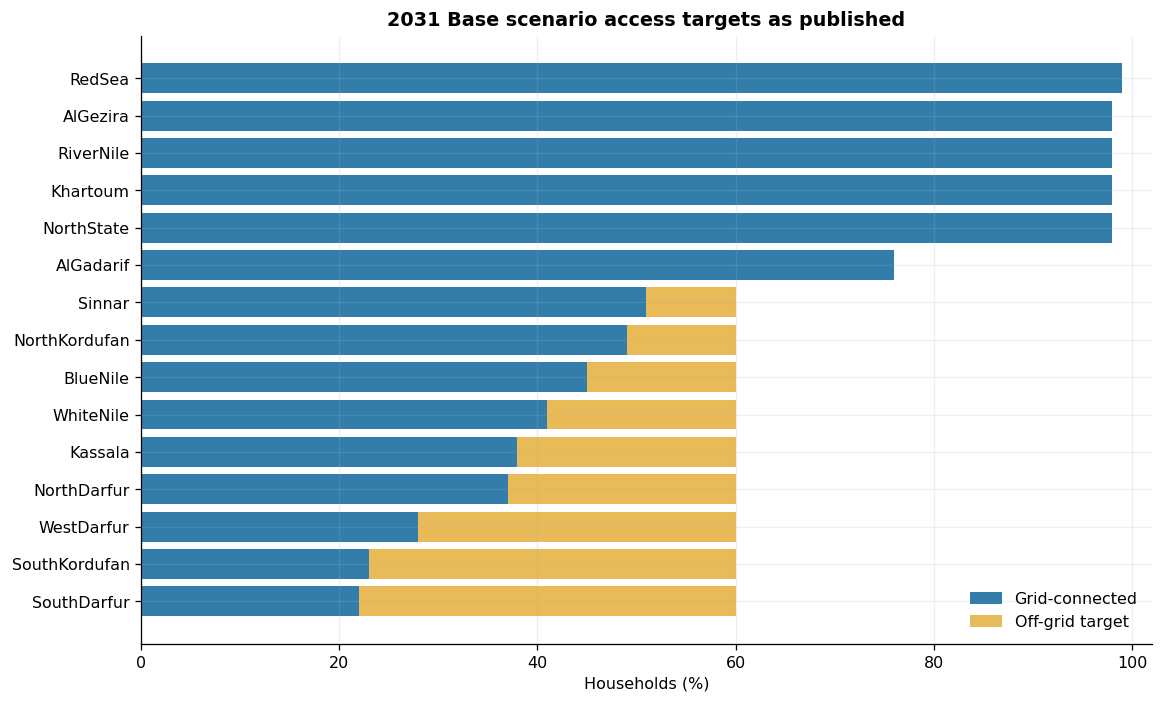

,voltage_kv,number_of_lines,total_length_km,pdf_page,source_id
0,500,3,966,56,MWRE_Lahmeyer_2012_260690
1,220,28,5286,56,MWRE_Lahmeyer_2012_260690
2,110,27,1100,56,MWRE_Lahmeyer_2012_260690
3,66,5,293,56,MWRE_Lahmeyer_2012_260690


,state,route,length_km,voltage_kv
0,Al Gezira,Mashkur - Managil,80,220
1,Al Gezira,Managil - Marinjan,65,220
2,Red Sea,PortSudan-1 - PortSudan-2,30,220
3,Red Sea,PortSudan-1 - FreeZone,30,220
4,Red Sea,FreeZone - Swaken,31,220
5,Red Sea,Swaken - Tokar,100,220
6,Red Sea,Tokar - Groura,105,220
7,Red Sea,Sinkat - Haya,75,220
8,Red Sea,Arkeyi - Portsudan-2,75,220
9,Red Sea,Aroma - Durdeab,195,220


In [10]:
loc_summary=localities.groupby('state').agg(localities=('locality_id','count'),population_2008=('population_2008','sum'),
                                           households_2008=('households','sum'))
display(loc_summary)
print('Unconnected localities with zero listed distance:',
      ((localities.national_grid_2012=='no')&(localities.distance_to_national_grid_km==0)).sum())
last=access[(access.year==2031)&(~access['aggregate'])]
display(last.groupby('scenario').overall_pct.min().rename('minimum_state_access_in_annex_pct').to_frame())
base=last[last.scenario=='Base'].set_index('state').sort_values('grid_pct')
fig,ax=plt.subplots(figsize=(10,6),layout='constrained')
ax.barh(base.index,base.grid_pct,color='#337dab',label='Grid-connected')
ax.barh(base.index,base.offgrid_target_pct,left=base.grid_pct,color='#e8bb58',label='Off-grid target')
ax.set(xlabel='Households (%)',title='2031 Base scenario access targets as published',xlim=(0,102));ax.legend(frameon=False)
finish('08_electrification_targets')
display(read('transmission_summary_2012'))
display(read('planned_transmission_routes_2012')[['state','route','length_km','voltage_kv']].head(12))

## 10. Validation results and unresolved source conflicts

Arithmetic checks allow for rounding of independently printed totals. They validate extraction and visible identities, not the underlying forecast's predictive accuracy. Cross-table disagreements are reported separately and must not be made to disappear by adjusting source numbers.

In [11]:
# Fixed source spot-checks guard against scenario, year and column shifts.
assert national.query("scenario=='Base' and year==2022").billed_gwh.item()==23067
assert national.query("scenario=='High' and year==2031").peak_mw.item()==8361
assert plants.set_index('plant_id').loc['M-HP','gross_capacity_mw']==1250
assert hydro.query("plant_id=='M-HP' and month==1").mean_generation_mwh_per_day.item()==14028
assert len(localities)==131 and localities.locality_id.nunique()==131
assert len(history)==480 and len(monthly)==720
assert not national.duplicated(['scenario','year']).any()
assert not monthly.duplicated(['scenario','year','month']).any()
assert national.billed_gwh.notna().all() and hydro.mean_generation_mwh_per_day.notna().all()
validation=pd.DataFrame(checks)
validation.to_csv(RESULTS/'validation_checks.csv',index=False)
display(validation.round(4))
assert validation.passed.all(), 'Investigate failed checks; do not ignore them.'

state_total=states[states.state=='Sudan total'].merge(national,on=['scenario','year'])
state_peak_difference=(state_total.load_at_system_peak_mw-state_total.peak_mw).abs().max()
mid=national.pivot(index='year',columns='scenario',values='billed_gwh')
midpoint_difference=(mid.Base-(mid.Moderate+mid.High)/2).abs().max()
issues=pd.DataFrame([
    ['Annual versus monthly energy',f'Maximum difference {month_year.energy_difference_gwh.abs().max():,.0f} GWh/year','132–133','Different annex dates; do not combine without reconciliation'],
    ['State versus national peak',f'Maximum difference {state_peak_difference:,.0f} MW','126–131','Retain separate series; not rounding alone'],
    ['Base versus output midpoint',f'Maximum billed-energy difference {midpoint_difference:,.1f} GWh','126,128,130','Base is not exactly the arithmetic midpoint of all published outputs'],
    ['Monthly reserve','273–277 MW early years; 534 MW from 2017','103,132–133','Annual annex uses 15%; compare explicit reserve policies'],
    ['2016 available capacity','Annual annex: 2,940 MW; monthly August and main Table 7-1: 2,810 MW','109,132–133','Retain both source values; mixed revisions or assumptions require clarification'],
    ['Missing capacity','February–December 2031: 11 months blank for each scenario','133','Preserve missing values; no automatic imputation'],
    ['Hydro annual reconciliation','Roseires and Sennar monthly mean energy differs materially from annual planned mean','120–121','Use a declared source hierarchy; calibrate annual energy separately'],
    ['Hydro capacity basis','Merowe dependable 1,250 MW exceeds tabulated net maximum 1,237.5 MW','120–121','Do not use unchecked p_max_pu > 1; resolve gross/net basis'],
    ['Thermal efficiency','Al Fula and Kosti heat-rate-derived full-load efficiencies differ from listed 36.7%','120–121','Preserve both values until technical validation'],
    ['Off-grid target','Moderate narrative minimum 50%; annex minimum 60% in 2031','87,127','State the chosen interpretation'],
    ['Planned assets','Red Sea, Al Fula and Sennar upgrading were not started as of the 2019 cross-check','120; external WB Table 1.1','Do not treat 2012 committed status as evidence of operation in 2022'],
    ['Asset replacement','Roseires heightening and Sennar upgrading repeat original plant locations/capacity configurations','120–121','Choose one configuration per asset and year'],
    ['Geographic definitions','15 historical states; population and household totals vary with table scope','114–115,123–124','Reconcile boundaries and source years; no fabricated current-state allocation'],
],columns=['issue','finding','pdf_pages','treatment'])
issues.to_csv(RESULTS/'source_issues.csv',index=False)
display(issues)

,check,maximum_absolute_error,tolerance,unit,n_compared,passed
0,Sequential loss reconstruction,0.8716,1.00,GWh,60,True
1,Printed energy accounting,1.0000,1.00,GWh,60,True
2,Sector consumption adds to national,2.0000,3.00,GWh,60,True
3,Load factor agrees within printed precision,0.3453,0.51,percentage points,60,True
4,Historical state sums versus national by year/sector,3.0000,8.00,GWh,30,True
5,Annual reserve = 15% peak,0.5500,0.60,MW,60,True
6,Annual power gap arithmetic,1.0000,1.00,MW,60,True
7,Annual energy gap arithmetic,1.0000,1.00,GWh,60,True
8,Monthly power gap arithmetic where capacity exists,1.0000,1.00,MW,687,True
9,Monthly energy gap arithmetic,1.0000,1.00,GWh,720,True


,issue,finding,pdf_pages,treatment
0,Annual versus monthly energy,"Maximum difference 1,022 GWh/year",132–133,Different annex dates; do not combine without reconciliation
1,State versus national peak,Maximum difference 237 MW,126–131,Retain separate series; not rounding alone
2,Base versus output midpoint,Maximum billed-energy difference 258.5 GWh,"126,128,130",Base is not exactly the arithmetic midpoint of all published outputs
3,Monthly reserve,273–277 MW early years; 534 MW from 2017,"103,132–133",Annual annex uses 15%; compare explicit reserve policies
4,2016 available capacity,"Annual annex: 2,940 MW; monthly August and main Table 7-1: 2,810 MW","109,132–133",Retain both source values; mixed revisions or assumptions require clarification
5,Missing capacity,February–December 2031: 11 months blank for each scenario,133,Preserve missing values; no automatic imputation
6,Hydro annual reconciliation,Roseires and Sennar monthly mean energy differs materially from annual planned mean,120–121,Use a declared source hierarchy; calibrate annual energy separately
7,Hydro capacity basis,"Merowe dependable 1,250 MW exceeds tabulated net maximum 1,237.5 MW",120–121,Do not use unchecked p_max_pu > 1; resolve gross/net basis
8,Thermal efficiency,Al Fula and Kosti heat-rate-derived full-load efficiencies differ from listed 36.7%,120–121,Preserve both values until technical validation
9,Off-grid target,Moderate narrative minimum 50%; annex minimum 60% in 2031,"87,127",State the chosen interpretation


## 11. Independent reality check and source register

The [World Bank's 2019 diagnostic](https://documents1.worldbank.org/curated/en/486961588608080192/pdf/From-Subsidy-to-Sustainability-Diagnostic-Review-of-Sudan-Electricity-Sector.pdf), Table 1.1, provides a later implementation check. Kosti entered service in 2015 and Upper Atbara in 2018; Red Sea, Al Fula and Sennar upgrading were listed as not started. The table also distinguishes Roseires dam heightening from a separate proposed capacity upgrade. This confirms that planned commissioning dates cannot serve as observed asset data.

The register below identifies the original owners and where their data appear in the supplied PDF. Public links are explicitly labelled as related sources when they are not the exact original utility workbooks. No original calculation workbook is embedded in the supplied PDF.

In [12]:
display(read('implementation_crosscheck_2019')[['project','status_as_of_2019','capacity_scope']])
source_register=read('source_register')
display(source_register[['source_key','data_group','owner','vintage','availability']])

,project,status_as_of_2019,capacity_scope
0,Kosti,commissioned in 2015,500 MW (4 x 125)
1,Upper Atbara,commissioned in 2018,320 MW
2,Roseires dam heightening,completed in 2013,"280 MW, changed dam; not an additional 280 MW plant"
3,Red Sea 1 and 2,not started as of 2019,600 MW (2 x 300)
4,Al Fula 1–3,not started as of 2019,405 MW (3 x 135)
5,Sennar upgrading,not started as of 2019,26 MW


,source_key,data_group,owner,vintage,availability
0,S01,Supplied report,Lahmeyer International / MWRE,2012 final revision,User-supplied PDF; SHA256 in source_metadata.json
1,S02,Demography,Central Bureau of Statistics (CBS),2008 census; 2009–2031 projections,Named in report; related official microdata catalog found
2,S03,Administrative geography,"CBS, UN and Lahmeyer",15-state historical boundaries,Named in report; exact GIS files not supplied
3,S04,GDP,CBS and IMF World Economic Outlook,2000–2011; WEO 2012,IMF publication landing page located; exact edition used by report not specified
4,S05,Urbanisation,UN-HABITAT,The State of African Cities 2010,Official publication found
5,S06,Metered consumption and customers,MED / SEDCo,Mostly 2006–2011,Named in report; exact utility workbooks not supplied
6,S07,System metering,Load Dispatch Centre,Historic through 2011/2012,Named in report; original time series not supplied
7,S08,Generation,MED and Lahmeyer,Existing and committed as assessed in 2012,Substantial technical table available in annex
8,S09,Transmission and distribution,MED / SETCo / SEDCo and Lahmeyer,Network / project status around 2012,Tables and schematic available; exact model files not supplied
9,S10,Planning criteria,Sudan regulatory authority / Grid Code,Version used in 2012 report,Named but full Grid Code not supplied


## 12. How this improves the post-war least-cost electrification study

The report materially improves the **historical evidence base**: plant-level engineering assumptions, hydro seasonality, regional consumption and a locality framework. It does not supply post-war damage or the investment-cost inputs needed to solve least-cost electrification.

| Use now | Necessary treatment before the main model |
|---|---|
| Plant coordinates, fuel and heat rates | Match to the 2022 asset list; select surviving units; flag technical conflicts |
| Monthly hydro characteristics | Use as a documented seasonal prior; calibrate to 2022 generation and test wet/dry alternatives; avoid double-counting Roseires |
| 2011 state-sector consumption | Use as a fallback allocation with sensitivity bounds; reconcile state boundaries and calibrate to 2022 national consumption |
| Locality population and grid distances | Treat as historical access priors; update population/displacement, routes and service levels |
| Network project tables and single-line diagram | Verify construction and condition; acquire actual endpoints, circuit ratings and repair options |
| Historical O&M | Retain as old benchmarks; update price year, fuel cost and repair cost separately |

For the research question, define a planning horizon such as **2030/2035 as a study assumption**, then minimize discounted investment, repair, fuel and operating cost while meeting explicit access and reliability targets. Compare grid rehabilitation/extension, utility renewables and storage, mini-grids, and standalone supply. PyPSA can represent generation, storage and the bulk grid; settlement connection choices need explicit connection/distribution costs and service constraints, either within a coupled formulation or through a linked geospatial electrification model.

Priority missing inputs are: (1) damage/repair and availability scenarios; (2) settlement demand including displaced/returning households and productive use; (3) grid-extension, distribution, mini-grid and standalone capital costs; (4) renewable time series and land/resource constraints; (5) consistent fuel/import costs, discount rates, construction limits and reliability targets. Where evidence is unavailable, label these as scenarios and test sensitivity instead of presenting them as observations.

**Replication boundary.** We recovered the printed forecasts and engineering tables, reconstructed sequential losses and adequacy arithmetic, and exposed source conflicts. We cannot regenerate the complete locality-by-locality forecasting engine from raw inputs, exact hourly load shapes from plotted curves, or an optimal investment plan from this demand report alone. The highest-value additional document is the companion **Expansion Candidates Report**, together with the original demand workbook and SETCo/SEDCo datasets requested in Annex 1.

In [13]:
summary={
    'report_date':'2012-10-18','plant_configuration_records':len(plants),'localities':len(localities),
    'national_scenario_years':len(national),'monthly_scenario_records':len(monthly),
    'national_metrics':read('national_forecast_long').metric.nunique(),
    'raw_tables':int(json.loads((ROOT/'source_metadata.json').read_text())['raw_table_count']),
    'max_loss_reconstruction_error_gwh':float(recalc.energy_error_gwh.abs().max()),
    'max_annual_monthly_energy_difference_gwh':float(month_year.energy_difference_gwh.abs().max()),
    'max_state_national_peak_difference_mw':float(state_peak_difference),
    'checks_passed':int(validation.passed.sum()),'checks_total':len(validation),
    'scope':'Partial replication of published outputs and visible arithmetic; not a complete forecasting-workbook or optimization replication',
}
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2))
versions={'python':platform.python_version()}
for package in ['pandas','numpy','matplotlib','nbformat','nbclient','nbconvert']:
    versions[package]=importlib.metadata.version(package)
(RESULTS/'runtime_versions.json').write_text(json.dumps(versions,indent=2))
display(Markdown(f"**Completed:** {summary['checks_passed']}/{summary['checks_total']} arithmetic checks within stated rounding tolerances. Source discrepancies are retained in `results/source_issues.csv`."))

**Completed:** 10/10 arithmetic checks within stated rounding tolerances. Source discrepancies are retained in `results/source_issues.csv`.